# Exploration of: Cognitive Distortion detetction dataset

link of the website: 
https://www.kaggle.com/datasets/sagarikashreevastava/cognitive-distortion-detetction-dataset?select=Annotated_data.csv


## Imports

In [110]:
import pandas as pd
import numpy as np

import string

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer

In [111]:
data = pd.read_csv("/Users/abiboubou/code/youhsuanchang/project/archive-2/Annotated_data.csv")
data.head()
data.shape

(2530, 5)

In [112]:
data["Patient Question"]

0       Hello, I have a beautiful,smart,outgoing and a...
1       Since I was about 16 years old I’ve had these ...
2        So I’ve been dating on and off this guy for a...
3       My parents got divorced in 2004. My mother has...
4       I don’t really know how to explain the situati...
                              ...                        
2525    I’m a 21 year old female. I spent most of my l...
2526    I am 21 female and have not had any friends fo...
2527    From the U.S.: My brother is 19 years old and ...
2528    From the U.S.: I am a 21 year old woman who ha...
2529    I recently moved out on my ex-roommate because...
Name: Patient Question, Length: 2530, dtype: object

In [113]:
thrapist_response_data = pd.read_csv("/Users/abiboubou/code/youhsuanchang/project/archive-2/Therapist_responses.csv")
thrapist_response_data.head()

,Answer,Question,Id_Number
0,Thank you for writing. You did nothing wrong! ...,From a teen in Australia: This story is incred...,0
1,"At 63, you are still working on this. For that...",From a woman in the U.S.: My Therapist of eigh...,1
2,It’s impossible to give a diagnosis over the i...,I don’t even really know where to start. For t...,2
3,Congratulations on bringing your new baby into...,"From a woman in the UK: Hi, I have a 4 month o...",3
4,Thank you for explaining this situation. How u...,Me and my sister in law are both pregnant righ...,4


In [114]:
X = data[["Patient Question"]]
X.head()

,Patient Question
0,"Hello, I have a beautiful,smart,outgoing and a..."
1,Since I was about 16 years old I’ve had these ...
2,So I’ve been dating on and off this guy for a...
3,My parents got divorced in 2004. My mother has...
4,I don’t really know how to explain the situati...


# Features (Patience Questions)

### Length 
num_of_unique_questions = 2529,
max length of the phrases = ,
min length of the phrases = ,
mean length of the phrases = ,

In [115]:
X.shape

(2530, 1)

In [116]:
X.duplicated().value_counts()

False    2529
True        1
Name: count, dtype: int64

In [117]:
data.duplicated().value_counts()#->there is one question is the same but other informtion are not the same

False    2530
Name: count, dtype: int64

In [118]:
X[X.duplicated(keep=False)]

,Patient Question
464,I grew up in a upper middle class family. I wa...
506,I grew up in a upper middle class family. I wa...


In [119]:
X = X.drop_duplicates()
X.head()

,Patient Question
0,"Hello, I have a beautiful,smart,outgoing and a..."
1,Since I was about 16 years old I’ve had these ...
2,So I’ve been dating on and off this guy for a...
3,My parents got divorced in 2004. My mother has...
4,I don’t really know how to explain the situati...


In [120]:
num_of_unique_questions = X.shape[0]
num_of_unique_questions

2529

## Data Cleaning

In [121]:
def cleaning(sentence):

    # Basic cleaning
    sentence = sentence.strip() ## remove whitespaces
    sentence = sentence.lower() ## lowercase
    sentence = ''.join(char for char in sentence if not char.isdigit()) ## remove numbers

    # Advanced cleaning
    for punctuation in string.punctuation:
        sentence = sentence.replace(punctuation, '') ## remove punctuation

    tokenized_sentence = word_tokenize(sentence) ## tokenize
    stop_words = set(stopwords.words('english')) ## define stopwords

    tokenized_sentence_cleaned = [ ## remove stopwords
        w for w in tokenized_sentence if not w in stop_words
    ]

    lemmatized = [
        WordNetLemmatizer().lemmatize(word, pos = "v")
        for word in tokenized_sentence_cleaned
    ]

    cleaned_sentence = ' '.join(word for word in lemmatized)

    return cleaned_sentence


In [122]:
cleaned_documents = X["Patient Question"].apply(cleaning)
cleaned_documents

0       hello beautifulsmartoutgoing amaze five year o...
1       since years old ’ “ spell ” ’ impossible contr...
2       ’ date guy almost years years younger relation...
3       parent get divorce mother never recover severe...
4       ’ really know explain situation deal lot famil...
                              ...                        
2525    ’ year old female spend life isolate violent f...
2526    female friends years high achieve score really...
2527    us brother years old currently live parent col...
2528    us year old woman seriously involve older man ...
2529    recently move exroommate history psyche proble...
Name: Patient Question, Length: 2529, dtype: object

In [123]:
vectorizer = TfidfVectorizer()

vectorized_documents = vectorizer.fit_transform(cleaned_documents)
vectorized_documents = pd.DataFrame(
    vectorized_documents.toarray(),
    columns = vectorizer.get_feature_names_out()
)

vectorized_documents

,aa,ab,aback,abandon,abandonment,abcdxyz,abdomen,abdominal,abdominoplasty,abhor,...,zing,zip,zits,zoloft,zombie,zombies,zone,zyclidine,zyprexa,zyrtec
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2524,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2525,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2526,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2527,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [124]:
data['text_word_count'] = data["Patient Question"].fillna('').str.split().str.len()
data.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN,447
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN,181
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295


In [125]:
data['text_word_count'].describe

<bound method NDFrame.describe of 0       131
1       292
2       447
3       181
4       295
       ... 
2525     72
2526    191
2527     80
2528     69
2529     91
Name: text_word_count, Length: 2530, dtype: int64>

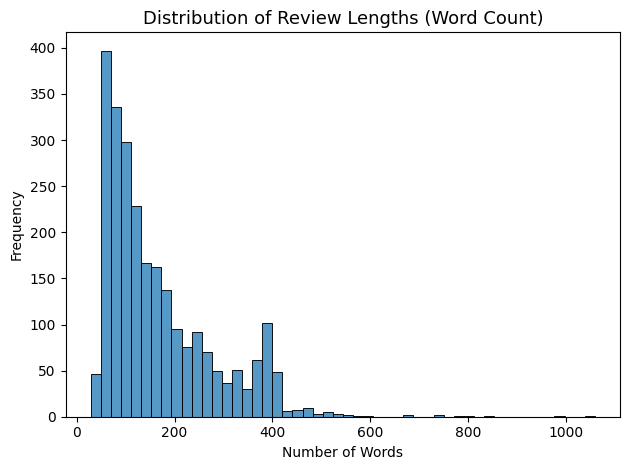

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.histplot(data=data, x='text_word_count')

plt.title('Distribution of Review Lengths (Word Count)', fontsize=13)
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [127]:
infos = {
  "mean": [167.3],
  "min": [29],
  "max" : [1059]
}

feature_infos = pd.DataFrame(infos)
feature_infos


,mean,min,max
0,167.3,29,1059


In [128]:
data["Patient Question"].nunique()

2529

# Target (Distortion)

In [129]:
data.head()

,Id_Number,Patient Question,Distorted part,Dominant Distortion,Secondary Distortion (Optional),text_word_count
0,4500,"Hello, I have a beautiful,smart,outgoing and a...",The voice are always fimilar (someone she know...,Personalization,NaN,131
1,4501,Since I was about 16 years old I’ve had these ...,I feel trapped inside my disgusting self and l...,Labeling,Emotional Reasoning,292
2,4502,So I’ve been dating on and off this guy for a...,NaN,No Distortion,NaN,447
3,4503,My parents got divorced in 2004. My mother has...,NaN,No Distortion,NaN,181
4,4504,I don’t really know how to explain the situati...,I refused to go because I didn’t know if it wa...,Fortune-telling,Emotional Reasoning,295


In [136]:
data["Dominant Distortion"].value_counts()

Dominant Distortion
No Distortion              933
Mind Reading               239
Overgeneralization         239
Magnification              195
Labeling                   165
Personalization            153
Fortune-telling            143
Emotional Reasoning        134
Mental filter              122
Should statements          107
All-or-nothing thinking    100
Name: count, dtype: int64

In [132]:
data["Dominant Distortion"].nunique()

11

In [ ]:
data["Dominant Distortion"].value_counts(normalize=True)